# 환경 세팅

In [59]:
import random
import numpy as np
import torch

# 재현율 - 시드 고정
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 같은 입력에 같은 결과를 내는 합성곱 알고리즘
torch.backends.cudnn.deterministic = True
# 여러 알고리즘의 속도를 측정 및 가장 빠른것을 고르는 기능 (끄기)
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

DEVICE


device(type='cuda')

# 데이터셋 준비

In [60]:
from torchvision.datasets import ImageFolder

train_dataset = ImageFolder(root="datas/train")
val_dataset = ImageFolder(root="datas/val")

In [61]:
train_dataset.classes, train_dataset.class_to_idx

(['0_fingers', '2_fingers', '5_fingers'],
 {'0_fingers': 0, '2_fingers': 1, '5_fingers': 2})

In [62]:
import numpy as np

# 크기 체크
np.asarray(train_dataset[0][0], dtype=np.float64).shape

(3060, 4080, 3)

In [63]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(10, 9))

# 각 클래스를 순회하기. [0_fingers -> 2_fingers -> 5_fingers]
for row, class_name in enumerate(train_dataset.classes):
    # 인덱스 가져오기 (0, 1, 2)
    train_label = train_dataset.class_to_idx[class_name]
    val_label = val_dataset.class_to_idx[class_name]

    # trarget 번호를 가져오기. [인덱스, 라벨_클래스]
    train_indices = [i for i, label in enumerate(train_dataset.targets) if label == train_label]
    val_indices = [i for i, label in enumerate(val_dataset.targets) if label == val_label]

    # 훈련[0, 1] 검증[0] 으로 1행 3열 만들기
    samples = [
        (train_dataset, train_indices[0], 'Train 1'),
        (train_dataset, train_indices[1], 'Train 2'),
        (val_dataset, val_indices[0], 'Val'),
    ]

    # ax에 추가해주기. 
    for col, (dataset, index, split) in enumerate(samples):
        ax = axes[row, col]
        ax.imshow(dataset[index][0])
        ax.set_title(f'{class_name} | {split}')
        ax.axis('off')

fig.tight_layout()
plt.show()


KeyboardInterrupt: 

# 평균과 표준편차

In [ ]:
# 훈련 이미지 전체의 RGB 픽셀 통계 (0~1 범위)
pixel_sum = np.zeros(3, dtype=np.float64)
pixel_sq_sum = np.zeros(3, dtype=np.float64)
pixel_count = 0

for image, _ in train_dataset:
    # 이미지를 numpy 형태로 변경해줍니다.
    # pixels의 형태는 (H, W, C) 형태에서 3차원이기 떄문에 이를 H*W, C 형태로 변환하며 uint8 범위인 255로 정규화해줍니다.
    pixels = np.asarray(image, dtype=np.float64).reshape(-1, 3) / 255.0
    # 모든 이미지들의 채널별 픽셀값의 합을 잡아줍니다.
    # 형태는 0차원이 압축되어 (3,)가 됩니다.
    pixel_sum += pixels.sum(axis=0)
    # 이후에는 제곱합을 통해 분산을 구할 준비를 함
    # 원래라면 (갑 - 평균)^2 형태이지만 순회를 줄이기 위해 이렇게 진행
    pixel_sq_sum += (pixels ** 2).sum(axis=0)
    # H*W 누적
    pixel_count += pixels.shape[0]

# 평균은 쉽게 픽셀 개수로 나눠주면 (3,)
train_mean = pixel_sum / pixel_count
# 표준편차의 경우에는 
train_std = np.sqrt(
  # 소수점 오차 방지
  np.maximum(
    # 픽셀을 제곱한 값의 평균을 먼저 구합니다.
    pixel_sq_sum / pixel_count 
    # 그리고 위에서 구한 평균의 제곱을 뺴주면 
    - train_mean ** 2,
    0
  )
)

print("훈련 픽셀 평균 (R, G, B):", train_mean)
print("훈련 픽셀 표준편차 (R, G, B):", train_std)

훈련 픽셀 평균 (R, G, B): [0.4637346  0.43781324 0.41661853]
훈련 픽셀 표준편차 (R, G, B): [0.33807545 0.32283665 0.31226071]


> 위 표준편차 구하기의 참고 수식

$$
\frac{1}{N}\sum(x_i-\mu)^2
=
\frac{1}{N}\sum(x_i^2-2x_i\mu+\mu^2)
$$

$$
=
\frac{\sum x_i^2}{N}
-2\mu\frac{\sum x_i}{N}
+\frac{N\mu^2}{N}
$$

$$
=
\frac{\sum x_i^2}{N}-2\mu^2+\mu^2
=
\frac{\sum x_i^2}{N}-\mu^2
$$

# 정규화 전후 픽셀 최대/최소 출력 (+통계)

In [ ]:
import pandas as pd
from IPython.display import display

# 원본 픽셀(0~1)과 정규화한 픽셀의 통계를 비교합니다.
# 훈련과 검증 모두 훈련에서 구한 train_mean, train_std를 사용합니다.
def get_channel_stats(dataset):
    # [학습, 검증][R, G, B] -> (2, 3)
    total = np.zeros((2, 3), dtype=np.float64)
    # 제곱 총 합
    squared_total = np.zeros((2, 3), dtype=np.float64)
    # 최대/최소를 저장함. 
    minimum = np.full((2, 3), np.inf)
    maximum = np.full((2, 3), -np.inf)
    count = 0

    # 지정된 데이터셋 (훈련 또는 검증)으로 가져와주기
    for image, _ in dataset:
        # 픽셀 전체 가져와서 (H*W, C) 형태로 바꿔서 255로 나누어 정규화
        pixels = np.asarray(image, dtype=np.float64).reshape(-1, 3) / 255.0
        # 픽셀 개수 누적
        count += pixels.shape[0]

        # stage-0은 정규화 전
        # stage-1은 정규화 후
        for stage in range(2):
            if stage == 1:
                pixels = (pixels - train_mean) / train_std
            # 총 합 저장. (C,) 형태로 생성
            total[stage] += pixels.sum(axis=0)
            # 제곱합 저장 (C,)
            squared_total[stage] += (pixels ** 2).sum(axis=0)
            # 최소/최대 설정
            minimum[stage] = np.minimum(minimum[stage], pixels.min(axis=0))
            maximum[stage] = np.maximum(maximum[stage], pixels.max(axis=0))

    mean = total / count
    std = np.sqrt(np.maximum(squared_total / count - mean ** 2, 0))
    return mean, std, minimum, maximum

rows = []
for dataset_name, dataset in [('훈련', train_dataset), ('검증', val_dataset)]:
    means, stds, minimums, maximums = get_channel_stats(dataset)
    for stage, stage_name in enumerate(['정규화 전', '정규화 후']):
        for channel, channel_name in enumerate(['R', 'G', 'B']):
            rows.append({
                '데이터셋': dataset_name,
                '단계': stage_name,
                '채널': channel_name,
                '평균': means[stage, channel],
                '표준편차': stds[stage, channel],
                '최소': minimums[stage, channel],
                '최대': maximums[stage, channel],
            })

pixel_stats_df = pd.DataFrame(rows)
display(pixel_stats_df.round(6))


,데이터셋,단계,채널,평균,표준편차,최소,최대
0,훈련,정규화 전,R,0.463735,0.338075,0.000000,1.000000
1,훈련,정규화 전,G,0.437813,0.322837,0.000000,1.000000
2,훈련,정규화 전,B,0.416619,0.312261,0.000000,1.000000
3,훈련,정규화 후,R,-0.000000,1.000000,-1.371690,1.586230
4,훈련,정규화 후,G,-0.000000,1.000000,-1.356145,1.741397
5,훈련,정규화 후,B,-0.000000,1.000000,-1.334201,1.868251
6,검증,정규화 전,R,0.458707,0.335974,0.000000,1.000000
7,검증,정규화 전,G,0.435360,0.323292,0.000000,1.000000
8,검증,정규화 전,B,0.415032,0.315050,0.000000,1.000000
9,검증,정규화 후,R,-0.014871,0.993786,-1.371690,1.586230


# Transformer 준비

In [ ]:
from torchvision import transforms

data_transforms = {
    "train": transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomAffine(
            degrees=5,
            translate=(0.05, 0.05),
            scale=(0.95, 1.05),
        ),
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean=train_mean.tolist(), std=train_std.tolist()),
    ]),
    "val": transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
        transforms.Normalize(mean=train_mean.tolist(), std=train_std.tolist()),
    ]),
}

# 모델 생성 (파라미터 수)
조건에는 파라미터가 5만개 이하라고 했는데 Conv2d 2개 + FC 레이어로 128x128 이미지를 다루는건 뭔가 애매하다 생각하여 일단 소극적으로 잡았습니다.

> 아마 transforms에서 Resize로 3060x4080 이미지를 128x128로 바꾸어서 너무 작게 느껴지는 것일 수 있습니다. 일단 작업을 하며 알아볼 예정입니다.

In [ ]:
import torch.nn as nn

class HandShapeCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            # 3, 128, 128
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            # 16, 128, 128
            nn.ReLU(),
            nn.MaxPool2d(2),
            # 16, 64, 64
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            # 32, 64, 64
            nn.ReLU(),
            nn.MaxPool2d(2),
            # 32, 32, 32
            nn.AdaptiveAvgPool2d((8, 8)),
            # 32, 8, 8
        )
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(32 * 8 * 8, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        return self.fc(x)

model = HandShapeCNN(num_classes=3)
print(model)
print('파라미터 수:', sum(p.numel() for p in model.parameters()))


HandShapeCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(8, 8))
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=2048, out_features=3, bias=True)
)
파라미터 수: 11235


In [ ]:
import torch

# model은 optimizer를 만들기 전에 사용할 device로 이동해둡니다.
def run_epoch(model, loader, criterion, optimizer=None):
    # 모델을 이용해서 device 동기화
    device = next(model.parameters()).device
    # criterion은 배치 평균 loss를 반환하는 reduction='mean' 기준입니다.
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.set_grad_enabled(is_train):
        for images, labels in loader:
            # device 맞추기
            images = images.to(device)
            labels = labels.to(device)

            # grad 초기화
            if is_train:
                optimizer.zero_grad()

            # 예측 및 loss
            logits = model(images)
            loss = criterion(logits, labels)

            # 훈련이면 미분 누적 및 합산
            if is_train:
                loss.backward()
                optimizer.step()

            # 마지막 배치 크기가 달라도 샘플 수 기준으로 평균을 냅니다.
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

    if total_samples == 0:
        raise ValueError('loader에 데이터가 없습니다.')

    avg_loss = total_loss / total_samples
    avg_acc = total_correct / total_samples
    return avg_loss, avg_acc


# 실패하는 학습

In [ ]:
from torch.utils.data import DataLoader

# 원본 데이터셋은 그대로 두고, transforms를 적용하는 데이터셋 생성
train_data = ImageFolder(root='datas/train', transform=data_transforms['train'])
val_data = ImageFolder(root='datas/val', transform=data_transforms['val'])

# 데이터 수가 36개(train) 이기 때문에 좀 적게 잡았습니다
batch_size = 8
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=0)

In [ ]:
model = HandShapeCNN().to(DEVICE)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

EPOCH = 5

for epoch in range(1, EPOCH+1):
  train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
  val_loss, val_acc = run_epoch(model, val_loader, criterion)

  print(f"epoch: {epoch} | train_loss: {train_loss:.4f} | train_acc: {train_acc:.4f} | val_loss: {val_loss:.4f} | val_acc: {val_acc:.4f}")


epoch: 1 | train_loss: 1.1261 | train_acc: 0.2500 | val_loss: 1.0941 | val_acc: 0.3333
epoch: 2 | train_loss: 1.1001 | train_acc: 0.2778 | val_loss: 1.0773 | val_acc: 0.6667
epoch: 3 | train_loss: 1.0683 | train_acc: 0.5000 | val_loss: 1.0681 | val_acc: 0.3333
epoch: 4 | train_loss: 1.0333 | train_acc: 0.4722 | val_loss: 1.0451 | val_acc: 0.5000
epoch: 5 | train_loss: 1.0324 | train_acc: 0.4444 | val_loss: 1.0129 | val_acc: 0.5000


# 왜 0.5가 나오나....
이번에 돌린 버전은 처음에 재현성을 맨 위에서 하지 않아서 다시 초기화하고 run all 을 하였습니다.

resize 압축률이 굉장히 크고 (3060x4080 -> 128x128), CNN 레이어도 단순하였으며 증강이 데이터셋에 비해 다채로웠음에도 어느정도 acc가 0.66이 나오는 것이 확인됩니다. 조금 더 학습률을 높여서 확실하게 실패하겠습니다.

In [ ]:
model = HandShapeCNN().to(DEVICE)
criterion = torch.nn.CrossEntropyLoss()
# 학습률 x10
optimizer = torch.optim.AdamW(model.parameters(), lr=0.01)

EPOCH = 5

for epoch in range(1, EPOCH+1):
  train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
  val_loss, val_acc = run_epoch(model, val_loader, criterion)

  print(f"epoch: {epoch} | train_loss: {train_loss:.4f} | train_acc: {train_acc:.4f} | val_loss: {val_loss:.4f} | val_acc: {val_acc:.4f}")

epoch: 1 | train_loss: 1.9361 | train_acc: 0.3056 | val_loss: 1.0984 | val_acc: 0.3333
epoch: 2 | train_loss: 1.0990 | train_acc: 0.3333 | val_loss: 1.0986 | val_acc: 0.3333
epoch: 3 | train_loss: 1.0990 | train_acc: 0.2500 | val_loss: 1.0987 | val_acc: 0.3333
epoch: 4 | train_loss: 1.0988 | train_acc: 0.3333 | val_loss: 1.0987 | val_acc: 0.3333
epoch: 5 | train_loss: 1.0988 | train_acc: 0.3333 | val_loss: 1.0987 | val_acc: 0.3333


## 실패 완료.
일단 학습률을 높게 먹이니 학습하는 8개(마지막에 4개) 데이터셋을 통해 업데이트가 많이 되어 적은 데이터셋 만으로 안정성을 잡기 어려운 상태가 되었음을 확인할 수 있었습니다. 

## 성공 목표 및 계획

이에 따라 다시 검증 정확도 `0.75` 이상(4개중 3개)을 목표로 수치를 만들어 보겠습니다.

batch를 조금 더 줄여서 4로 만들고 epoch를 늘리면 되지 않을까 싶습니다.

In [ ]:
batch_size = 4
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=0)

model = HandShapeCNN().to(DEVICE)
criterion = torch.nn.CrossEntropyLoss()
# 업데이트 크기를 줄이기 위해 학습률을 낮춥니다.
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

EPOCH = 20

for epoch in range(1, EPOCH+1):
  train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
  val_loss, val_acc = run_epoch(model, val_loader, criterion)

  print(f"epoch: {epoch} | train_loss: {train_loss:.4f} | train_acc: {train_acc:.4f} | val_loss: {val_loss:.4f} | val_acc: {val_acc:.4f}")

epoch: 1 | train_loss: 1.1139 | train_acc: 0.3333 | val_loss: 1.0859 | val_acc: 0.3333
epoch: 2 | train_loss: 1.1013 | train_acc: 0.2500 | val_loss: 1.0661 | val_acc: 0.4167
epoch: 3 | train_loss: 1.0618 | train_acc: 0.4722 | val_loss: 1.0106 | val_acc: 0.6667
epoch: 4 | train_loss: 1.0370 | train_acc: 0.5556 | val_loss: 0.9552 | val_acc: 0.7500
epoch: 5 | train_loss: 0.9904 | train_acc: 0.7222 | val_loss: 0.9188 | val_acc: 0.7500
epoch: 6 | train_loss: 0.9674 | train_acc: 0.5556 | val_loss: 0.8718 | val_acc: 0.5000
epoch: 7 | train_loss: 0.8196 | train_acc: 0.7222 | val_loss: 0.7893 | val_acc: 0.7500
epoch: 8 | train_loss: 0.7317 | train_acc: 0.6944 | val_loss: 0.6885 | val_acc: 0.7500
epoch: 9 | train_loss: 0.7531 | train_acc: 0.6944 | val_loss: 0.6784 | val_acc: 0.6667
epoch: 10 | train_loss: 0.7461 | train_acc: 0.7222 | val_loss: 0.5999 | val_acc: 0.7500
epoch: 11 | train_loss: 0.6817 | train_acc: 0.6667 | val_loss: 0.6149 | val_acc: 0.6667
epoch: 12 | train_loss: 0.6820 | train_ac

# 검증 데이터 돌려보면서 틀리는 부분들만 출력

,0-finger 확률,2-finger 확률,5-finger 확률,예측,실제,맞음 여부
인덱스,,,,,,
0,0.95,0.04,0.01,0_fingers,0_fingers,True
1,0.71,0.26,0.03,0_fingers,0_fingers,True
2,0.59,0.39,0.02,0_fingers,0_fingers,True
3,0.13,0.78,0.09,2_fingers,0_fingers,False
4,0.05,0.84,0.11,2_fingers,2_fingers,True
5,0.01,0.91,0.08,2_fingers,2_fingers,True
6,0.08,0.62,0.30,2_fingers,2_fingers,True
7,0.01,0.85,0.14,2_fingers,2_fingers,True
8,0.06,0.39,0.55,5_fingers,5_fingers,True


틀린 이미지: 1장


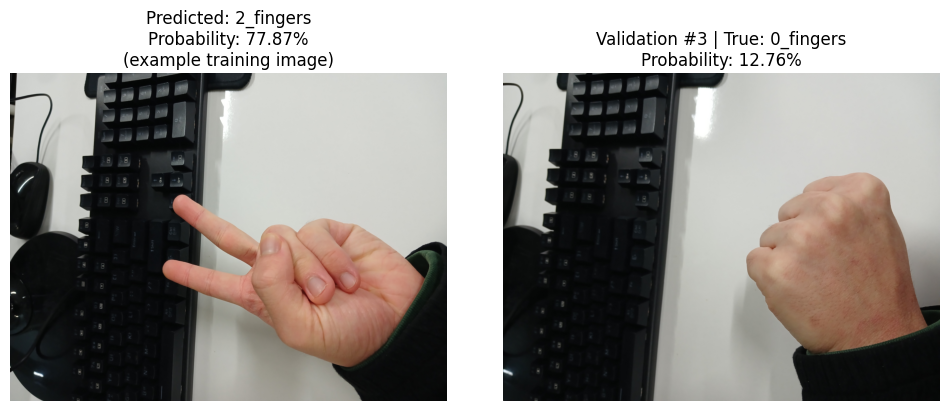

In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

model.eval()
device = next(model.parameters()).device
class_names = val_loader.dataset.classes

rows = []
records = []

# 현재 val_loader는 shuffle=False 기준입니다.
with torch.no_grad():
    for images, labels in val_loader:
        logits = model(images.to(device))
        probabilities = torch.softmax(logits, dim=1).cpu()
        predictions = probabilities.argmax(dim=1)

        for image, label, pred, probs in zip(
            images, labels, predictions, probabilities
        ):
            index = len(records)
            actual = label.item()
            predicted = pred.item()

            row = {"인덱스": index}
            row.update({
                f"{name.split('_')[0]}-finger 확률": round(probs[i].item(), 2)
                for i, name in enumerate(class_names)
            })
            row.update({
                "예측": class_names[predicted],
                "실제": class_names[actual],
                "맞음 여부": predicted == actual,
            })
            rows.append(row)
            records.append((image.cpu(), actual, predicted, probs))

# 1. 검증 이미지 전체 표
result_df = pd.DataFrame(rows).set_index("인덱스")
display(result_df.round(4))

# 2. 틀린 이미지 선택
wrong_indices = result_df.index[~result_df["맞음 여부"]].tolist()

if wrong_indices:
    selected_indices = wrong_indices
    print(f"틀린 이미지: {len(wrong_indices)}장")
else:
    # 모두 맞으면 정답 클래스 확률이 낮은 이미지 2장 선택
    selected_indices = sorted(
        range(len(records)),
        key=lambda i: records[i][3][records[i][1]].item()
    )[:2]
    print("모두 정답입니다. 정답 확률이 낮은 이미지 2장을 표시합니다.")

fig, axes = plt.subplots(
    len(selected_indices), 2,
    figsize=(10, 4 * len(selected_indices)),
    squeeze=False
)

for row, index in enumerate(selected_indices):
    image, actual, predicted, probs = records[index]

    # 틀렸으면 예측 클래스, 모두 맞았으면 두 번째 후보 클래스
    comparison = (
        predicted if wrong_indices
        else probs.argsort(descending=True)[1].item()
    )
    comparison_name = class_names[comparison]

    # 비교할 클래스의 학습 원본 이미지 한 장
    train_label = train_dataset.class_to_idx[comparison_name]
    example_index = next(
        i for i, label in enumerate(train_dataset.targets)
        if label == train_label
    )
    example_path = train_dataset.samples[example_index][0]
    example_image = train_dataset.loader(example_path)

    axes[row, 0].imshow(example_image)
    comparison_title = "Predicted" if wrong_indices else "Runner-up"
    axes[row, 0].set_title(
        f"{comparison_title}: {comparison_name}\n"
        f"Probability: {probs[comparison].item():.2%}\n"
        "(example training image)"
    )

    # 검증 이미지의 정규화를 되돌립니다.
    # image = image.permute(1, 2, 0).numpy()
    # image = np.clip(image * train_std + train_mean, 0, 1)

    image = val_dataset.loader(val_dataset.samples[index][0])
    axes[row, 1].imshow(image)
    axes[row, 1].set_title(
        f"Validation #{index} | True: {class_names[actual]}\n"
        f"Probability: {probs[actual].item():.2%}"
    )

    for ax in axes[row]:
        ax.axis("off")

fig.tight_layout()
plt.show()

# 틀린 원인 추측
위에서 예측하였을 때 우측은 2-finger로 나왔지만 실제는 오른쪽 이미지의 주먹이였습니다. (가위 이미지는 그냥 예시이며 실제로는 36장 이미지 전체를 보고 종합적으로 예측한 결과일 것입니다.)

중요한 것은 주먹을 보고 2-finger이라고 예측했다는 부분인데 이는 주먹과 5-finger은 확실한 차이가 보일 수 있는데 2-finger은 두 손가락을 제외한 전체적인 특징 (손등이나 엄지손가락 모양 등)이 비슷하기 떄문에 이를 세세하게 걸러내지 못 한 것으로 추측됩니다.

이를 해결하기 위해선 아마 더 많은 이미지 또는 정제된 질 좋은 데이터셋이 필요 할 것 같습니다. 

데이터 수를 늘리는 경우에는 어떤 느낌도 괜찮을 것 같으며 질을 높이기 위해서는 정말 전방위 각도에서 뽑고 고르게 분포되어있는 이미지를 확인하는 것이 좋을 것 같습니다.

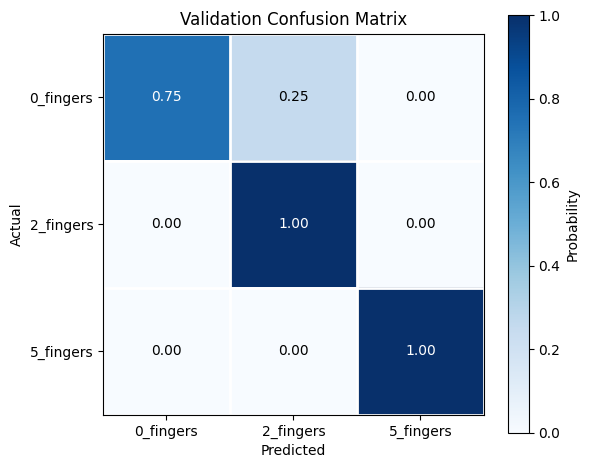

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

row_counts = confusion_matrix.sum(axis=1, keepdims=True)
confusion_prob = np.divide(
    confusion_matrix,
    row_counts,
    out=np.zeros_like(confusion_matrix, dtype=float),
    where=row_counts != 0
)

fig, ax = plt.subplots(figsize=(6, 5))

heatmap = ax.imshow(
    confusion_prob,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(3), labels=class_names)
ax.set_yticks(range(3), labels=class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Validation Confusion Matrix")

# 각 칸에 확률 표시
for row in range(3):
    for col in range(3):
        probability = confusion_prob[row, col]
        ax.text(
            col, row, f"{probability:.2f}",
            ha="center", va="center",
            color="white" if probability > 0.5 else "black"
        )

# 칸 사이 경계선
ax.set_xticks(np.arange(4) - 0.5, minor=True)
ax.set_yticks(np.arange(4) - 0.5, minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)

fig.colorbar(heatmap, ax=ax, label="Probability")
fig.tight_layout()
plt.show()

# 최종 정리
아무튼 그리드로 표현을 해도 결국 val_loader은 `shuffle=False`이기 때문에 동일하게 `0-finger` 에서 가장 많이 섞임을 알 수 있습니다. (`2-finger`과)